## Садиков_3826М1ПМвм1_2
### Лабораторная работа 2: Линейная регрессия
### Садиков Дамир. 3821М1ПМвм1. 2026

In [1]:
import sys
print(sys.version)

3.10.4 (tags/v3.10.4:9d38120, Mar 23 2022, 23:13:41) [MSC v.1929 64 bit (AMD64)]


## Цель работы

Цель практической работы — закрепить теоретические знания по линейной регрессии и освоить практические навыки построения, диагностики и улучшения регрессионных моделей на реальных данных о стоимости квартир Нижнего Новгорода

Для достижения целей работы будут выполнены следующие задания:
1. Конструирование признаков на основе площади и количества комнат
2. Диагностика остатков и проверка гипотез линейной модели
3. Кросс-валидация и сравнение схем разбиения
4. Устойчивость модели к выбросам: сравнение МНК, Huber и квантильной регрессии
5. Анализ ошибок по подгруппам и поиск «сложных» сегментов
6. Полиномиальные признаки и борьба с переобучением
7. Логарифмирование целевой переменной и интерпретация коэффициентов

## Считывание и очистка датасета

Загрузка сырых данных

In [2]:
import pandas as pd
url = "flats.csv"
data_raw = pd.read_csv(url)
print("Размер датасета:", data_raw.shape)
display(data_raw.head())
data_raw.info()

Размер датасета: (72379, 10)


,Price,Date,Lat,Lng,Type,Floors,Building,Rooms,Floor,Area
0,3500.0,240,56.365696,43.820250,Resale,9.0,Brick,3.0,4.0,60.0
1,4000.0,240,56.323057,44.007862,Resale,3.0,Brick,3.0,3.0,57.0
2,2150.0,240,56.267552,43.892107,Resale,5.0,Panel,2.0,1.0,38.0
3,3100.0,240,56.359963,43.813756,Resale,5.0,Panel,4.0,2.0,59.0
4,3585.0,240,56.325374,43.937463,Resale,9.0,Panel,2.0,7.0,52.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72379 entries, 0 to 72378
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Price     72379 non-null  float64
 1   Date      72379 non-null  int64  
 2   Lat       72379 non-null  float64
 3   Lng       72379 non-null  float64
 4   Type      72362 non-null  object 
 5   Floors    72362 non-null  float64
 6   Building  72362 non-null  object 
 7   Rooms     72362 non-null  float64
 8   Floor     72362 non-null  float64
 9   Area      72362 non-null  float64
dtypes: float64(7), int64(1), object(2)
memory usage: 5.5+ MB


Очистка датасета

In [3]:
data = data_raw.copy()
# Рассмотрим строки с пропущенными значениями
data[data.isna().any(axis=1)]

,Price,Date,Lat,Lng,Type,Floors,Building,Rooms,Floor,Area
4777,1400.0,56,56.326783,44.002687,NaN,NaN,NaN,NaN,NaN,NaN
4778,3000.0,57,56.229416,43.946365,NaN,NaN,NaN,NaN,NaN,NaN
4824,4950.0,62,56.283934,44.035397,NaN,NaN,NaN,NaN,NaN,NaN
4826,4100.0,56,56.341398,43.841083,NaN,NaN,NaN,NaN,NaN,NaN
4827,2900.0,56,56.272180,43.933501,NaN,NaN,NaN,NaN,NaN,NaN
4852,2400.0,56,56.327955,43.849715,NaN,NaN,NaN,NaN,NaN,NaN
5813,6000.0,62,56.283864,44.075417,NaN,NaN,NaN,NaN,NaN,NaN
5814,2350.0,62,56.326604,43.932114,NaN,NaN,NaN,NaN,NaN,NaN
6681,2950.0,62,56.348068,43.908636,NaN,NaN,NaN,NaN,NaN,NaN
6682,2390.0,63,56.201114,43.810028,NaN,NaN,NaN,NaN,NaN,NaN


Поскольку строк с пропущенными значениями незначительное количество относительно всей выборке и в них утрачены сразу многие значимые признаки, то проще всего исключить эти строки из рассмотрения

In [4]:
data = data.dropna()

Удалим дубликаты:

In [5]:
print("Количество дубликатов:", data.duplicated().sum())
data = data.drop_duplicates()

Количество дубликатов: 1210


Применим One-Hot Кодирование для категориальных признаков

In [6]:
display(data['Building'].unique())
display(data['Building'].unique())

from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded = encoder.fit_transform(data[['Building', 'Type']])

encoded_df = pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(),
    index=data.index
)

data = pd.concat([data.drop(columns=['Building', 'Type']), encoded_df], axis=1)

array(['Brick', 'Panel', 'Block', 'Monolithic', 'Wooden'], dtype=object)

array(['Brick', 'Panel', 'Block', 'Monolithic', 'Wooden'], dtype=object)

Борьба с выбросами. Ожидаем увидеть зависимость прежде всего между площадью и ценой. Поэтому рассмотрим диаграмму рассеивания по этим признакам

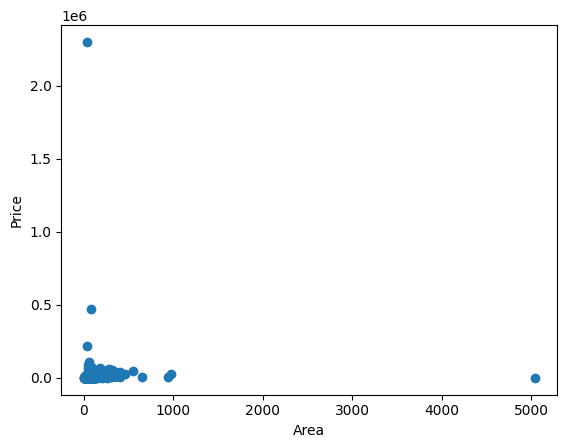

In [7]:
import matplotlib.pyplot as plt
plt.scatter(x='Area', y='Price', data=data)
plt.xlabel('Area')
plt.ylabel('Price')
pass

Из диаграммы рассеивания видно что в выборке присутствуют выбросы: объекты, значения площади или цены которых значительно отличаются от основной массы объектов. Удалим выбросы, выходящие за границы квантилей 0.005 и 0.995.

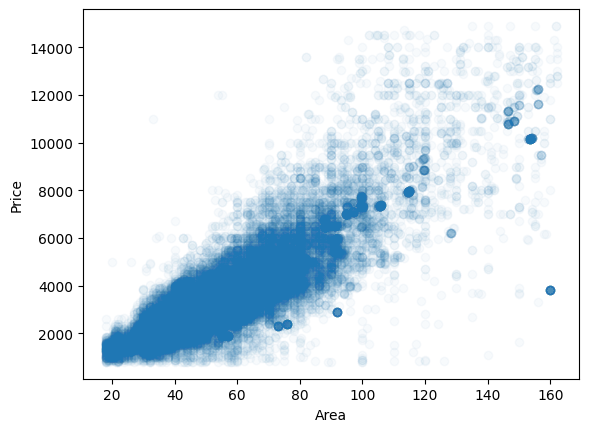

In [8]:
rows_to_drop = data[
    (data['Price'] < data['Price'].quantile(0.005)) |
    (data['Price'] > data['Price'].quantile(0.995)) |
    (data['Area'] < data['Area'].quantile(0.005)) |
    (data['Area'] > data['Area'].quantile(0.995))
].index
data = data.drop(rows_to_drop)
plt.scatter(x='Area', y='Price', data=data, alpha = .03)
plt.xlabel('Area')
plt.ylabel('Price')
pass

Теперь наглядно видно зависимость между площадью и ценой. Теперь проверим связь даты и цены

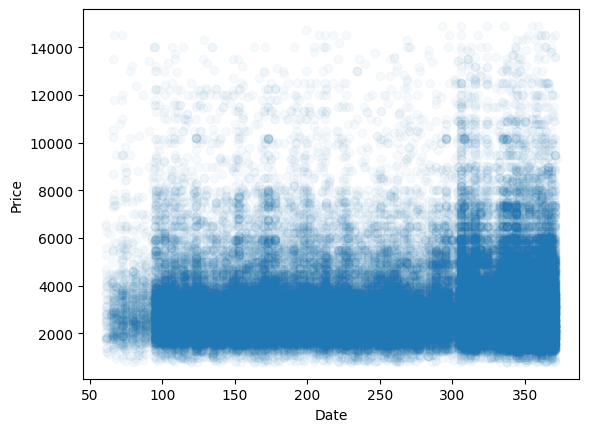

In [9]:
plt.scatter(x='Date', y='Price', data=data, alpha = .03)
plt.xlabel('Date')
plt.ylabel('Price')
pass

Из графика видно что полезной для нашей задачи связи даты и цены не наблюдается. Можем не использовать этот столбец в очищенном датасете

In [10]:
data = data.drop(columns=['Date'])

Проверим полученный датасет:

In [11]:
print("Размер исходного датасета:", data_raw.shape)
print("Размер очищенного датасета:", data.shape)

print("\nКоличество пропусков:")
print(data.isna().sum().sum())

print("\nТипы данных:")
print(data.dtypes)

display(data.head())

Размер исходного датасета: (72379, 10)
Размер очищенного датасета: (70045, 12)

Количество пропусков:
0

Типы данных:
Price                  float64
Lat                    float64
Lng                    float64
Floors                 float64
Rooms                  float64
Floor                  float64
Area                   float64
Building_Brick         float64
Building_Monolithic    float64
Building_Panel         float64
Building_Wooden        float64
Type_Resale            float64
dtype: object


,Price,Lat,Lng,Floors,Rooms,Floor,Area,Building_Brick,Building_Monolithic,Building_Panel,Building_Wooden,Type_Resale
0,3500.0,56.365696,43.820250,9.0,3.0,4.0,60.0,1.0,0.0,0.0,0.0,1.0
1,4000.0,56.323057,44.007862,3.0,3.0,3.0,57.0,1.0,0.0,0.0,0.0,1.0
2,2150.0,56.267552,43.892107,5.0,2.0,1.0,38.0,0.0,0.0,1.0,0.0,1.0
3,3100.0,56.359963,43.813756,5.0,4.0,2.0,59.0,0.0,0.0,1.0,0.0,1.0
4,3585.0,56.325374,43.937463,9.0,2.0,7.0,52.5,0.0,0.0,1.0,0.0,1.0


In [12]:
display(data.describe())

,Price,Lat,Lng,Floors,Rooms,Floor,Area,Building_Brick,Building_Monolithic,Building_Panel,Building_Wooden,Type_Resale
count,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000,70045.000000
mean,3312.172309,56.294946,43.935118,9.371761,1.945863,5.166993,52.385121,0.732029,0.063316,0.173431,0.003955,0.886616
std,1751.501577,0.044961,0.081732,5.123899,0.909084,3.863453,21.276194,0.442905,0.243533,0.378622,0.062762,0.317064
min,800.000000,54.862751,41.806470,1.000000,0.000000,1.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2200.000000,56.264893,43.868203,5.000000,1.000000,2.000000,37.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,2850.000000,56.299806,43.931336,9.000000,2.000000,4.000000,46.000000,1.000000,0.000000,0.000000,0.000000,1.000000
75%,3850.000000,56.325200,44.005232,12.000000,3.000000,7.000000,63.000000,1.000000,0.000000,0.000000,0.000000,1.000000
max,14900.000000,57.127867,44.485489,25.000000,6.000000,25.000000,162.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Задание 1. Конструирование признаков на основе площади и количества комнат

Создание производных признаков:

In [13]:
import numpy as np
data_model = data.copy()

data_model['Area_per_room'] = data_model['Area'] / (data_model['Rooms'] + 1)
data_model['Is_studio'] = (data_model['Rooms'] == 0).astype(int)
data_model['Floor_ratio'] = data_model['Floor'] / data_model['Floors']
data_model['Is_first_floor'] = (data_model['Floor'] == 1).astype(int)
data_model['Is_last_floor'] = (data_model['Floor'] == data_model['Floors']).astype(int)
data_model['Log_area'] = np.log1p(data_model['Area'])

display(data_model)

,Price,Lat,Lng,Floors,Rooms,Floor,Area,Building_Brick,Building_Monolithic,Building_Panel,Building_Wooden,Type_Resale,Area_per_room,Is_studio,Floor_ratio,Is_first_floor,Is_last_floor,Log_area
0,3500.000,56.365696,43.820250,9.0,3.0,4.0,60.0,1.0,0.0,0.0,0.0,1.0,15.000000,0,0.444444,0,0,4.110874
1,4000.000,56.323057,44.007862,3.0,3.0,3.0,57.0,1.0,0.0,0.0,0.0,1.0,14.250000,0,1.000000,0,1,4.060443
2,2150.000,56.267552,43.892107,5.0,2.0,1.0,38.0,0.0,0.0,1.0,0.0,1.0,12.666667,0,0.200000,1,0,3.663562
3,3100.000,56.359963,43.813756,5.0,4.0,2.0,59.0,0.0,0.0,1.0,0.0,1.0,11.800000,0,0.400000,0,0,4.094345
4,3585.000,56.325374,43.937463,9.0,2.0,7.0,52.5,0.0,0.0,1.0,0.0,1.0,17.500000,0,0.777778,0,0,3.979682
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72374,3250.000,56.282006,44.085056,14.0,1.0,1.0,44.7,0.0,1.0,0.0,0.0,1.0,22.350000,0,0.071429,1,0,3.822098
72375,2824.800,56.348480,43.873340,17.0,1.0,3.0,42.8,1.0,0.0,0.0,0.0,1.0,21.400000,0,0.176471,0,0,3.779634
72376,3316.125,56.300964,43.951468,25.0,2.0,5.0,55.5,0.0,1.0,0.0,0.0,0.0,18.500000,0,0.200000,0,0,4.034241
72377,13600.000,56.329327,44.014997,5.0,3.0,4.0,81.9,1.0,0.0,0.0,0.0,1.0,20.475000,0,0.800000,0,0,4.417635


Единое разбиение на train/test для всех вариантов тестирования

In [14]:
from sklearn.model_selection import train_test_split
train_idx, test_idx = train_test_split(data_model.index, test_size=0.2, random_state=42)

Для удобства выделим признаки для каждой из рассматриваемых моделей:
- features_base - Для модели использующей исходные признаки
- features_plus - Для модели с добавленными признаками
- features_log - Для модели, в которой Area заменена на Log_area

In [29]:
target_feature = 'Price'

features_base = data.columns.tolist()
features_base.remove(target_feature)

features_plus = data_model.columns.tolist()
features_plus.remove(target_feature)

features_log = features_base.copy()
features_log[features_log.index('Area')] = 'Log_area'

print('Целевой признак:', target_feature)
print('Исходные признаки:', features_base)
print('С производынми признаками:', features_plus)
print('Area_log вместо area:', features_log)

Целевой признак: Price
Исходные признаки: ['Lat', 'Lng', 'Floors', 'Rooms', 'Floor', 'Area', 'Building_Brick', 'Building_Monolithic', 'Building_Panel', 'Building_Wooden', 'Type_Resale']
С производынми признаками: ['Lat', 'Lng', 'Floors', 'Rooms', 'Floor', 'Area', 'Building_Brick', 'Building_Monolithic', 'Building_Panel', 'Building_Wooden', 'Type_Resale', 'Area_per_room', 'Is_studio', 'Floor_ratio', 'Is_first_floor', 'Is_last_floor', 'Log_area']
Area_log вместо area: ['Lat', 'Lng', 'Floors', 'Rooms', 'Floor', 'Log_area', 'Building_Brick', 'Building_Monolithic', 'Building_Panel', 'Building_Wooden', 'Type_Resale']


In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_metrics(features):
    X_train = data_model.loc[train_idx, features]
    X_test = data_model.loc[test_idx, features]
    y_train = data_model.loc[train_idx, target_feature]
    y_test = data_model.loc[test_idx, target_feature]

    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    predictions = lr_model.predict(X_test)

    metrics = {
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions)
    }
    return lr_model, metrics

model_base, metrics_base = calculate_metrics(features_base)
model_plus, metrics_plus = calculate_metrics(features_plus)
model_log, metrics_log = calculate_metrics(features_log)
print('Метрики для базовой модели:\n', metrics_base)
print('Метрики для модели c добавленными признаками:\n', metrics_plus)
print('Метрики для модели с Log_area:\n', metrics_log)

Метрики для базовой модели:
 {'MAE': 484.92042341031487, 'RMSE': 788.6315457023416, 'R2': 0.7974592900276681}
Метрики для модели c добавленными признаками:
 {'MAE': 470.6615570531687, 'RMSE': 776.6066742146207, 'R2': 0.8035887882778016}
Метрики для модели с Log_area:
 {'MAE': 609.4444957993652, 'RMSE': 937.7689827561372, 'R2': 0.713611373916601}


In [35]:
coefs = pd.DataFrame({
    'Feature': model_plus.feature_names_in_,
    'Coef': model_plus.coef_
})
#coefs = coefs[coefs['Feature'].isin(['Area_per_room', 'Is_studio', 'Floor_ratio', 'Is_first_floor', 'Is_last_floor', 'Log_area'])]

coefs = coefs.sort_values(
    by='Coef',
    key=abs,
    ascending=False
)

display(coefs)

,Feature,Coef
1,Lng,2802.371763
0,Lat,1523.386245
9,Building_Wooden,-630.835698
3,Rooms,-605.014476
13,Floor_ratio,-589.820535
16,Log_area,-541.292517
14,Is_first_floor,-367.425016
10,Type_Resale,186.963203
8,Building_Panel,-111.516726
5,Area,100.686042


## Задание 2. Диагностика остатков и проверка гипотез линейной модели

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Разделяем признаки и целевую переменную
X = data_model.drop(columns=['Price'])
y = data_model['Price']

# Разбиение 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Обучение модели
model = LinearRegression()
model.fit(X_train, y_train)

# Предсказания и остатки
y_pred = model.predict(X_test)
residuals = y_test - y_pred

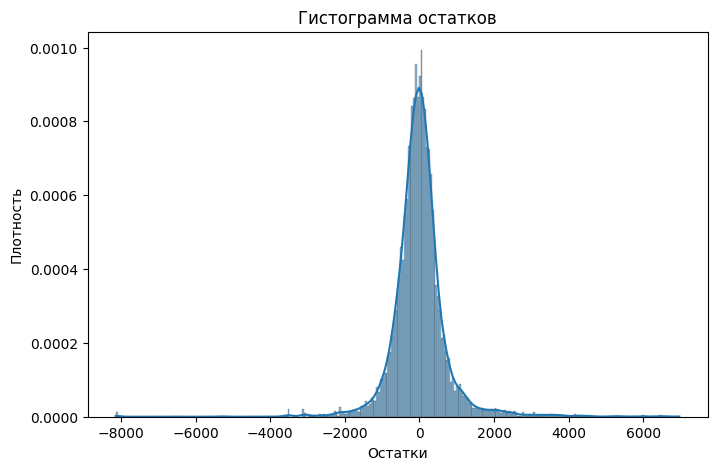

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True, stat='density')

plt.title('Гистограмма остатков')
plt.xlabel('Остатки')
plt.ylabel('Плотность')
plt.show()

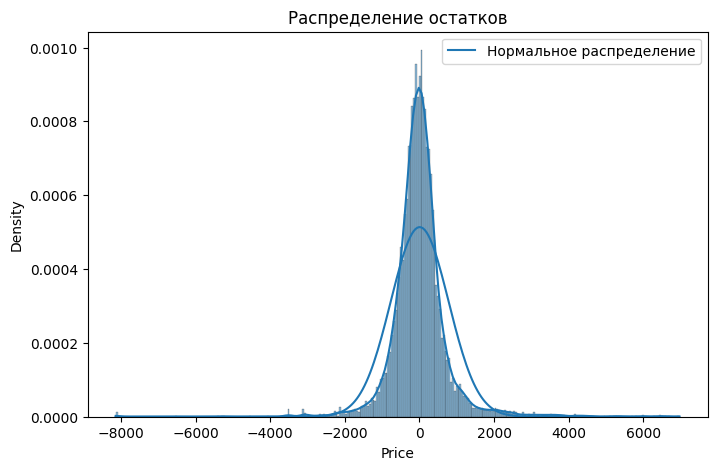

In [39]:
import numpy as np
from scipy.stats import norm

x = np.linspace(residuals.min(), residuals.max(), 300)

plt.figure(figsize=(8, 5))
sns.histplot(residuals, stat='density', kde=True)
plt.plot(x, norm.pdf(x, residuals.mean(), residuals.std()),
         label='Нормальное распределение')

plt.title('Распределение остатков')
plt.legend()
plt.show()

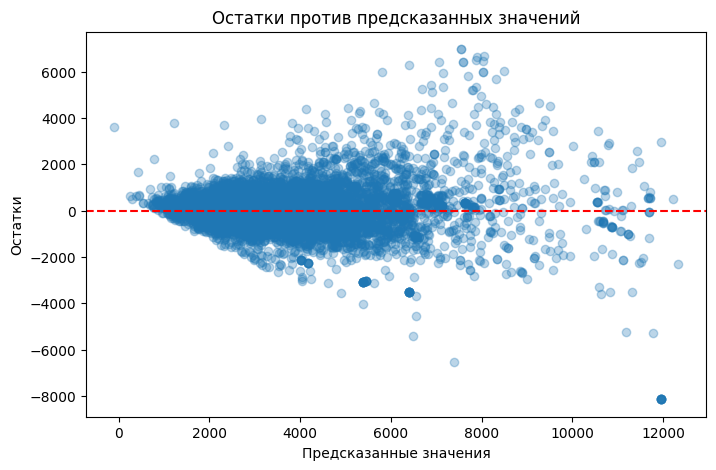

In [40]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Остатки против предсказанных значений')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.show()

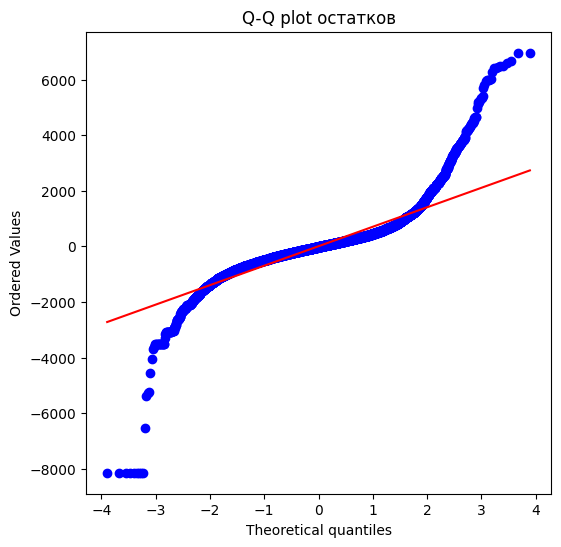

In [41]:
from scipy.stats import probplot

plt.figure(figsize=(6, 6))

probplot(residuals, dist='norm', plot=plt)

plt.title('Q-Q plot остатков')
plt.show()

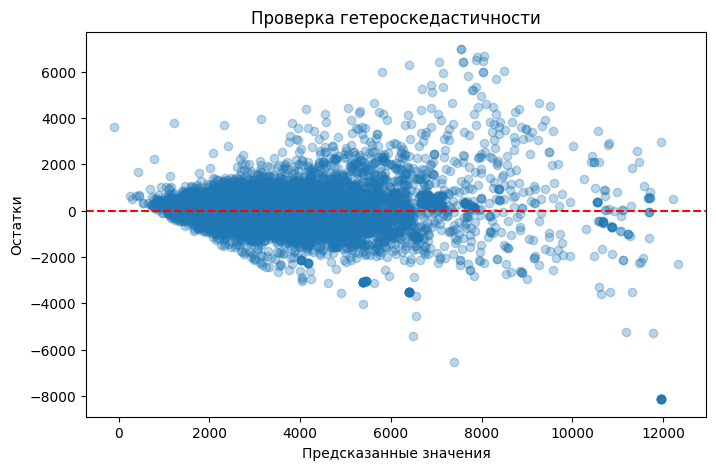

In [42]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')

plt.title('Проверка гетероскедастичности')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки')
plt.show()

In [43]:
corr = pd.Series(y_pred).corr(
    pd.Series(residuals.abs().values)
)

print(f'Корреляция: {corr:.4f}')

Корреляция: 0.4801


In [44]:
mean_residual = residuals.mean()

print(f'Среднее остатков: {mean_residual:.4f}')

Среднее остатков: 5.1841


In [45]:
numeric_features = X_test.select_dtypes(include='number').columns

corr_residuals = X_test[numeric_features].corrwith(residuals)

corr_residuals = corr_residuals.sort_values(
    key=abs,
    ascending=False
)

display(corr_residuals.to_frame('Correlation with residuals'))

,Correlation with residuals
Area,0.025881
Log_area,0.024499
Is_last_floor,0.023849
Rooms,0.021653
Lng,0.015613
Floors,-0.015174
Type_Resale,0.013645
Floor_ratio,0.011898
Building_Monolithic,-0.011468
Area_per_room,0.011430


In [46]:
test_data = data.loc[X_test.index].copy()
test_data['Residual'] = residuals

for col in ['Type', 'Building']:
    print(f'\nСредние остатки по {col}:')
    display(
        test_data.groupby(col)['Residual']
        .agg(['mean', 'count'])
        .sort_values('mean')
    )


Средние остатки по Type:


KeyError: 'Type'

## Задание 3. Кросс-валидация и сравнение схем разбиения

## Задание 4. Устойчивость модели к выбросам: сравнение МНК, Huber и квантильной регрессии

## Задание 5. Анализ ошибок по подгруппам и поиск «сложных» сегментов

## Задание 6. Полиномиальные признаки и борьба с переобучением

## Задание 7. Логарифмирование целевой переменной и интерпретация коэффициентов